病人ID        int64
年龄          int64
性别         object
地区         object
就诊日期       object
疾病类型       object
诊断日期       object
疾病严重程度     object
治疗方案       object
治疗结果       object
药物名称       object
药物分类       object
用药剂量       object
用药时长       object
检查项目       object
检查结果      float64
参考范围       object
体重        float64
身高        float64
吸烟情况       object
饮酒情况       object
遗传病史       object
dtype: object
(5440, 22)
病人ID       0
年龄         0
性别         0
地区         2
就诊日期       1
疾病类型       0
诊断日期      11
疾病严重程度     1
治疗方案       2
治疗结果       3
药物名称       2
药物分类       2
用药剂量       4
用药时长       2
检查项目       5
检查结果       3
参考范围       1
体重         3
身高         1
吸烟情况       3
饮酒情况       1
遗传病史       0
dtype: int64
    患者ID  年龄 性别  地区       就诊日期 疾病类型       诊断日期 疾病严重程度  治疗方案  治疗结果  ...  用药剂量  \
0  20413  45  女  重庆 2023-04-04   感冒 2023-04-25    不严重    放疗  病情稳定  ...  每周一次   
1  27375  38  女  深圳 2023-03-12   哮喘 2022-12-10    不严重    化疗    康复  ...  10毫克   
2  93406  27  女  武汉 2022-11-19   哮喘 2022

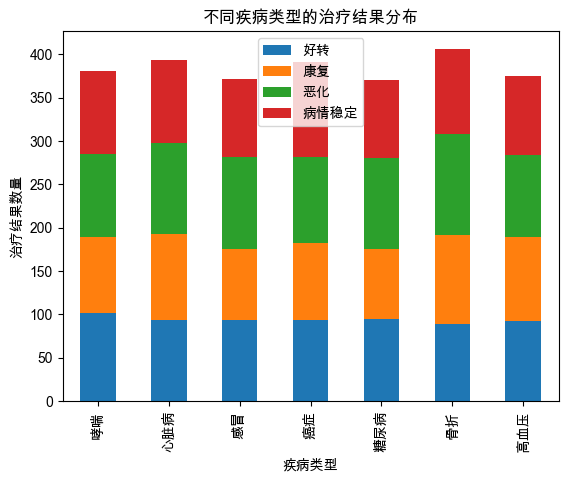

/var/folders/56/rsc52n_s7278yn_7pwsssx5c0000gp/T/ipykernel_22464/3978492573.py:75: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()  # 设置图例字体


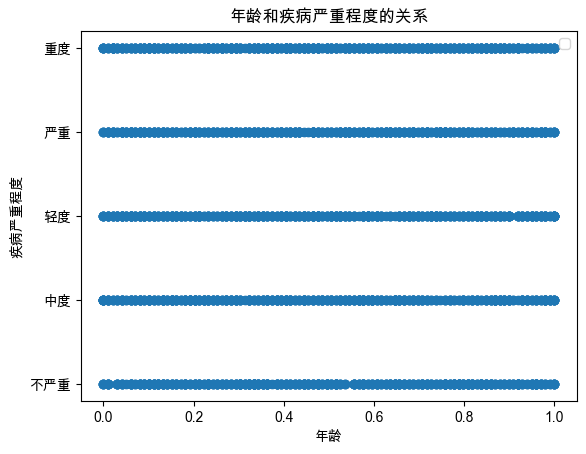

In [ ]:
import pandas as pd

# 加载数据集并指定编码为gbk
data = pd.read_csv('medical_data.csv', encoding='gbk')

# 查看数据类型
print(data.dtypes)
# 查看表结构基本信息
print(data.shape)

# 显示每一列的空缺值数量
print(data.isnull().sum())

# 规范日期格式
data['就诊日期'] = pd.to_datetime(data['就诊日期'])
data['诊断日期'] = pd.to_datetime(data['诊断日期'])

# 修改列名
data.rename(columns={'病人ID': '患者ID'}, inplace=True)

# 查看修改后的表结构
print(data.head())

from datetime import datetime

# 增加诊断延迟和病程列
data['诊断延迟'] = (data['诊断日期'] - data['就诊日期']).dt.days
data['病程'] = (datetime(2024, 9, 1) - data['诊断日期']).dt.days

# 删除不合理的数据
data = data[(data['诊断延迟'] >= 0) & (data['年龄'] > 0) & (data['年龄'] < 120)]

# 查看修改后的数据
print(data.describe())

# 删除重复值并记录删除的行数
initial_rows = data.shape[0]
data.dropna(inplace=True)
deleted_rows = initial_rows - data.shape[0]

print(f'删除的重复行数: {deleted_rows}')

from sklearn.preprocessing import MinMaxScaler

# 对需要归一化的列进行处理
scaler = MinMaxScaler()
columns_to_normalize = ['年龄', '体重',  '身高']
data[columns_to_normalize] = scaler.fit_transform(data[columns_to_normalize])

# 查看归一化后的数据
print(data.head())

import matplotlib.pyplot as plt

# 统计治疗结果分布
treatment_outcome_distribution = data.groupby('疾病类型')['治疗结果'].value_counts().unstack()

# 绘制柱状图
treatment_outcome_distribution.plot(kind='bar', stacked=True)
plt.title('不同疾病类型的治疗结果分布')
plt.xlabel('疾病类型')
plt.ylabel('治疗结果数量')
plt.show()

# 绘制散点图
plt.scatter(data['年龄'], data['疾病严重程度'])
plt.title('年龄和疾病严重程度的关系')
plt.xlabel('年龄')
plt.ylabel('疾病严重程度')
plt.show()

# 保存处理后得数据
output_path = '2.1.4_cleaned_data.csv'
data.to_csv(output_path, index=False)